In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


(73100, 9)
Accuracy: 0.909233926128591
AUC: 0.9521122197655834


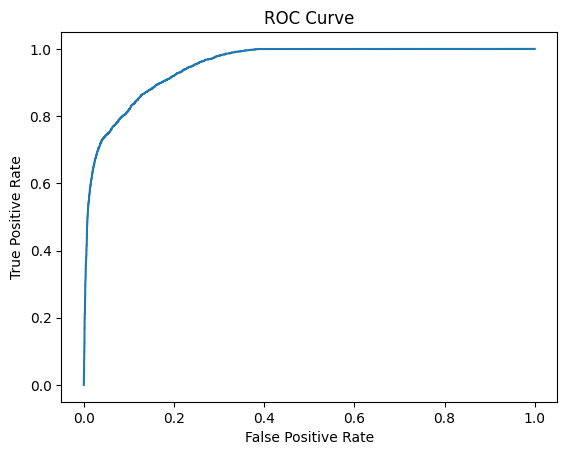

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_curve, roc_auc_score

# Load dataset
df = pd.read_csv("/content/drive/MyDrive/ML_LAB/RAIN.csv")
print(df.shape)

# Select input features
X = df[['Temperature', 'Humidity', 'Wind Speed',
        'Precipitation', 'Cloud Cover', 'Pressure']]

# Select target variable
y = df['Rain Tomorrow']

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create Logistic Regression model
model = LogisticRegression(max_iter=1000)

# Train model
model.fit(X_train, y_train)

# Predict class
y_pred = model.predict(X_test)

# Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

# Predict probability
y_probability = model.predict_proba(X_test)[:, 1]

# ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_probability)

# AUC
auc = roc_auc_score(y_test, y_probability)

print("AUC:", auc)

# Plot ROC Curve
plt.plot(fpr, tpr)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")

plt.show()